Libraries imported successfully!

Dataset loaded successfully!


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0



Dataset Shape:
(8128, 13)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   object 
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   object 
 5   seller_type    8128 non-null   object 
 6   transmission   8128 non-null   object 
 7   owner          8128 non-null   object 
 8   mileage        7907 non-null   object 
 9   engine         7907 non-null   object 
 10  max_power      7913 non-null   object 
 11  torque         7906 non-null   object 
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), object(9)
memory usage: 825.6+ KB

Statistical Description:


,year,selling_price,km_driven,seats
count,8128.000000,8.128000e+03,8.128000e+03,7907.000000
mean,2013.804011,6.382718e+05,6.981951e+04,5.416719
std,4.044249,8.062534e+05,5.655055e+04,0.959588
min,1983.000000,2.999900e+04,1.000000e+00,2.000000
25%,2011.000000,2.549990e+05,3.500000e+04,5.000000
50%,2015.000000,4.500000e+05,6.000000e+04,5.000000
75%,2017.000000,6.750000e+05,9.800000e+04,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,14.000000



Missing Values:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          221
engine           221
max_power        215
torque           222
seats            221
dtype: int64

Data cleaning completed!

Numerical Features: ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'seats']
Categorical Features: ['fuel', 'seller_type', 'transmission', 'owner']


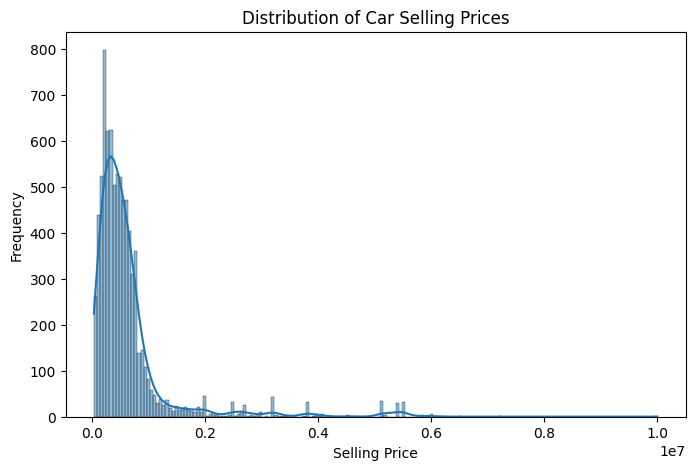


Training Data: (6502, 10)
Testing Data: (1626, 10)

Multiple Linear Regression Model Trained Successfully!

MODEL PERFORMANCE
MAE: 268886.6
MSE: 198038765899.45
RMSE: 445015.47
R2 Score: 0.6979


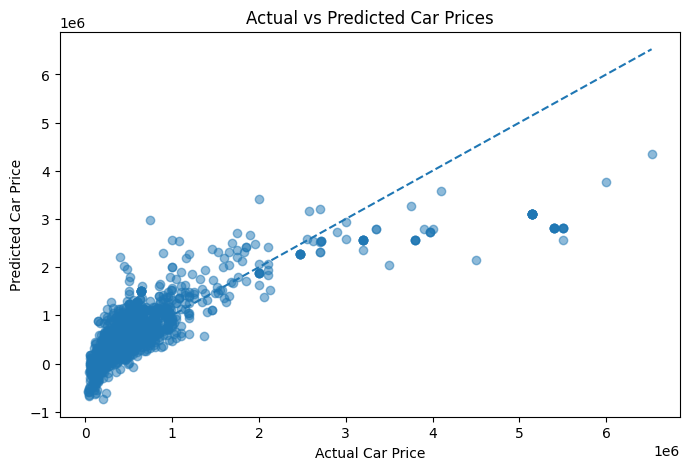


NEW CAR PRICE PREDICTION
Car Year: 2018
Kilometres Driven: 45000
Fuel: Diesel
Transmission: Manual

Predicted Selling Price: ₹ 887,996

CAR PRICE PREDICTION PROJECT COMPLETED!


In [2]:

# ============================================================
# CAR PRICE PREDICTION USING MULTIPLE LINEAR REGRESSION
# Platform: Anaconda Jupyter Notebook
# Dataset: Car Details V3
# ============================================================

# 1. IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")


# 2. LOAD DATASET

df = pd.read_csv("car details v3.csv")

print("\nDataset loaded successfully!")

display(df.head())


# 3. EXPLORE DATASET

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Description:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())


# 4. DATA CLEANING

# Remove unnecessary car name column
df = df.drop(columns=['name'], errors='ignore')

# Convert text-based numerical columns into numbers
numeric_text_columns = ['mileage', 'engine', 'max_power']

for col in numeric_text_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(
            df[col].astype(str).str.extract(
                r'(\d+\.?\d*)'
            )[0],
            errors='coerce'
        )

# Convert target into numeric format
df['selling_price'] = pd.to_numeric(
    df['selling_price'], errors='coerce'
)

# Remove rows without a valid target
df = df.dropna(subset=['selling_price'])

print("\nData cleaning completed!")


# 5. SELECT FEATURES AND TARGET

features = [
    'year',
    'km_driven',
    'fuel',
    'seller_type',
    'transmission',
    'owner',
    'mileage',
    'engine',
    'max_power',
    'seats'
]

# Keep only available required columns
features = [col for col in features if col in df.columns]

X = df[features]
y = df['selling_price']

# Identify numerical and categorical columns
numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("\nNumerical Features:", numerical_features)
print("Categorical Features:", categorical_features)


# 6. DATA VISUALIZATION

plt.figure(figsize=(8, 5))

sns.histplot(
    df['selling_price'],
    kde=True
)

plt.title("Distribution of Car Selling Prices")
plt.xlabel("Selling Price")
plt.ylabel("Frequency")
plt.show()


# 7. PREPROCESSING

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)


# 8. CREATE MULTIPLE LINEAR REGRESSION MODEL

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('regressor', LinearRegression())
])


# 9. TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


# 10. TRAIN THE MODEL

model.fit(X_train, y_train)

print("\nMultiple Linear Regression Model Trained Successfully!")


# 11. MAKE PREDICTIONS

y_pred = model.predict(X_test)


# 12. MODEL EVALUATION

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\n================================")
print("MODEL PERFORMANCE")
print("================================")

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))


# 13. ACTUAL VS PREDICTED VISUALIZATION

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")

plt.title("Actual vs Predicted Car Prices")

plt.show()


# 14. PREDICT PRICE OF A NEW CAR

new_car = pd.DataFrame([{
    'year': 2018,
    'km_driven': 45000,
    'fuel': 'Diesel',
    'seller_type': 'Individual',
    'transmission': 'Manual',
    'owner': 'First Owner',
    'mileage': 20.0,
    'engine': 1498,
    'max_power': 100.0,
    'seats': 5
}])

# Ensure the new car has the same input columns
new_car = new_car.reindex(columns=features)

predicted_price = model.predict(new_car)[0]

print("\n================================")
print("NEW CAR PRICE PREDICTION")
print("================================")

print("Car Year: 2018")
print("Kilometres Driven: 45000")
print("Fuel: Diesel")
print("Transmission: Manual")

print(
    "\nPredicted Selling Price: ₹",
    format(round(predicted_price), ',')
)


# 15. PROJECT COMPLETED

print("\nCAR PRICE PREDICTION PROJECT COMPLETED!")
